In [24]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import pandas as pd
import matplotlib.pyplot as plt

In [25]:
class Model(nn.Module):
    def __init__(self,in_features=4,h1=8,h2=9,out_features=3):
        super().__init__()
        self.fc1=nn.Linear(in_features,h1)
        self.fc2=nn.Linear(h1,h2)
        self.out=nn.Linear(h2,out_features)

    def forward(self,x):
        x=F.relu(self.fc1(x))
        x=F.relu(self.fc2(x))
        x=self.out(x)
        return x

In [26]:
torch.manual_seed(41)
model=Model()

In [27]:
#load iris dataset
url = 'https://gist.githubusercontent.com/netj/8836201/raw/6f9306ad21398ea43cba4f7d537619d0e07d5ae3/iris.csv'
df =pd.read_csv(url)
print(df.variety.unique())


<StringArray>
['Setosa', 'Versicolor', 'Virginica']
Length: 3, dtype: str


In [28]:
#df.variety=df.variety.map({'Setosa':1,'Versicolor':2,'Virginica':3})
df['variety']=df['variety'].replace('Setosa',0)
df['variety']=df['variety'].replace('Versicolor',1)
df['variety']=df['variety'].replace('Virginica',2)
df


,sepal.length,sepal.width,petal.length,petal.width,variety
0,5.1,3.5,1.4,0.2,0
1,4.9,3.0,1.4,0.2,0
2,4.7,3.2,1.3,0.2,0
3,4.6,3.1,1.5,0.2,0
4,5.0,3.6,1.4,0.2,0
...,...,...,...,...,...
145,6.7,3.0,5.2,2.3,2
146,6.3,2.5,5.0,1.9,2
147,6.5,3.0,5.2,2.0,2
148,6.2,3.4,5.4,2.3,2


In [29]:
X=df.drop('variety',axis='columns')
y=df.variety

In [30]:
#convert X ,y to numpy arrays
X=X.values
y=y.values

In [31]:
from sklearn.model_selection import train_test_split
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.2,random_state=41)

In [32]:
# Convert X features to float tensors
X_test=torch.FloatTensor(X_test)
X_train=torch.FloatTensor(X_train)

In [33]:
#astype(int)  bcs its object 
y_train = torch.LongTensor(y_train.astype(int) )
y_test = torch.LongTensor(y_test.astype(int) )

In [34]:
#messure the erro (how far the prediciton from the real value)
criterion=nn.CrossEntropyLoss()
#lr = learning rate (if error doesn't go down after a bunch of iterations (epochs), lower our learning rate)
optimizer=torch.optim.Adam(model.parameters(),lr=0.01)

In [37]:
# Train our model!
# Epochs? (one run thru all the training data in our network)
epochs=100
losses=[]
for i in range(epochs):
    # Go forward and get a prediction
    Y_predic=model.forward(X_train)
    # Measure the loss/error, gonna be high at first
    loss=criterion(Y_predic,y_train)
    # Keep Track of our losses
    losses.append(loss.detach().numpy())
    # print every 10 epoch
    if i % 10 == 0:
        print(f'Epoch: {i} and loss: {loss}')

    # Do some back propagation: take the error rate of forward propagation and feed it back
    # thru the network to fine tune the weights
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()
    



Epoch: 0 and loss: 1.125203251838684
Epoch: 10 and loss: 1.0097211599349976
Epoch: 20 and loss: 0.8162347078323364
Epoch: 30 and loss: 0.585993230342865
Epoch: 40 and loss: 0.4003389775753021
Epoch: 50 and loss: 0.26794716715812683
Epoch: 60 and loss: 0.1796349734067917
Epoch: 70 and loss: 0.12165624648332596
Epoch: 80 and loss: 0.0860651433467865
Epoch: 90 and loss: 0.06522615253925323


Text(0.5, 0, 'Epochs')

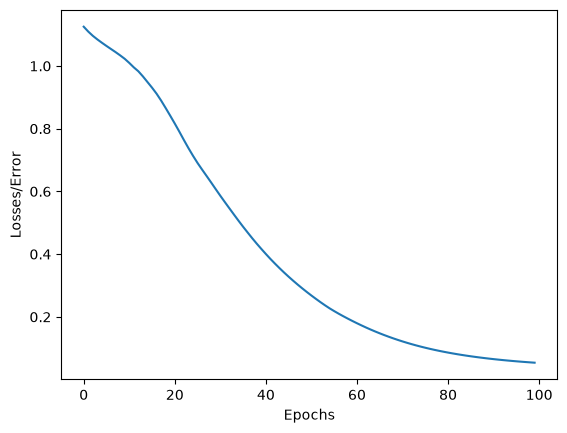

In [38]:
plt.plot(range(epochs),losses)
plt.ylabel('Losses/Error')
plt.xlabel('Epochs')

In [39]:
with torch.no_grad():
    y_eval=model.forward(X_test)
    loss=criterion(y_eval,y_test)
    

In [40]:
loss

tensor(0.1315)

In [41]:
correct = 0
with torch.no_grad():
  for i, data in enumerate(X_test):
    y_val = model.forward(data)

    if y_test[i] == 0:
      x = "Setosa"
    elif y_test[i] == 1:
      x = 'Versicolor'
    else:
      x = 'Virginica'


    # Will tell us what type of flower class our network thinks it is
    print(f'{i+1}.)  {str(y_val)} \t {y_test[i]} \t {y_val.argmax().item()}')

    # Correct or not
    if y_val.argmax().item() == y_test[i]:
      correct +=1

print(f'We got {correct} correct!')

1.)  tensor([-5.8771,  4.4629,  6.5155]) 	 2 	 2
2.)  tensor([-7.5451,  4.1668,  9.7293]) 	 2 	 2
3.)  tensor([-8.4517,  5.1275, 10.2015]) 	 2 	 2
4.)  tensor([-4.3411,  5.6280,  2.5636]) 	 1 	 1
5.)  tensor([-7.1838,  4.8757,  8.3023]) 	 2 	 2
6.)  tensor([-3.3940,  5.3421,  1.2802]) 	 1 	 1
7.)  tensor([-5.9240,  4.9826,  6.0025]) 	 2 	 2
8.)  tensor([-4.2895,  5.7016,  2.3920]) 	 1 	 1
9.)  tensor([-6.5369,  4.9261,  7.1291]) 	 2 	 2
10.)  tensor([-8.0526,  4.4129, 10.3325]) 	 2 	 2
11.)  tensor([-5.6775,  4.9505,  5.6248]) 	 2 	 2
12.)  tensor([ 4.5748, -2.2579, -2.8925]) 	 0 	 0
13.)  tensor([ 4.2646, -2.0055, -2.7342]) 	 0 	 0
14.)  tensor([-2.1081,  4.0482,  0.5803]) 	 1 	 1
15.)  tensor([ 3.4608, -1.2147, -2.3488]) 	 0 	 0
16.)  tensor([-5.4739,  5.1174,  5.0966]) 	 2 	 1
17.)  tensor([ 4.0637, -1.8045, -2.6504]) 	 0 	 0
18.)  tensor([-5.8090,  4.6057,  6.2494]) 	 1 	 2
19.)  tensor([ 4.9250, -2.5763, -3.0545]) 	 0 	 0
20.)  tensor([ 3.4559, -1.2559, -2.3637]) 	 0 	 0
21.)  ten

In [46]:
new_iris=torch.tensor([4.7, 3.2, 1.3, 0.2])

In [47]:

with torch.no_grad():
  print(model(new_iris))

tensor([ 4.5445, -2.2478, -2.8698])


In [48]:
# Save our NN Model
torch.save(model.state_dict(), 'my_really_awesome_iris_model.pt')

In [51]:
# Load the Saved Model
new_model = Model()
new_model.load_state_dict(torch.load('my_really_awesome_iris_model.pt'))

<All keys matched successfully>

In [52]:
# Make sure it loaded correctly
new_model.eval()

Model(
  (fc1): Linear(in_features=4, out_features=8, bias=True)
  (fc2): Linear(in_features=8, out_features=9, bias=True)
  (out): Linear(in_features=9, out_features=3, bias=True)
)